# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project

**Team Members:** Sergio Sanchez, Richard Fox

**Date:** October 2026

**GitHub Repository:** https://github.com/rfox7/Rich_Fox_-_AI-Portfolio/tree/main/ITAI2373-NewsBot-Midterm

**Dataset:** BBC News Classification (Kaggle) - https://www.kaggle.com/competitions/learn-ai-bbc/data

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Business, Entertainment, Politics, Sport, Tech)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [x] **Module 1:** NLP applications and real-world context
- [x] **Module 2:** Text preprocessing pipeline
- [x] **Module 3:** TF-IDF feature extraction
- [x] **Module 4:** POS tagging analysis
- [x] **Module 5:** Syntax parsing and semantic analysis
- [x] **Module 6:** Sentiment and emotion analysis
- [x] **Module 7:** Text classification system
- [x] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [2]:
# Install packages Colab doesn't include by default
# (pandas, scikit-learn, matplotlib, seaborn, nltk and spacy are already installed in Colab)
%pip install -q wordcloud plotly gradio
import sys
!{sys.executable} -m spacy download en_core_web_sm

# Download NLTK data
# Newer NLTK versions use 'punkt_tab' and 'averaged_perceptron_tagger_eng';
# the older names are kept so this works on any version.
import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'vader_lexicon',
            'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'universal_tagset']:
    nltk.download(pkg, quiet=True)

print("✅ All packages installed successfully!")


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.3/12.8 MB 6.5 MB/s eta 0:00:02
     ---- ----------------------------------- 1.3/12.8 MB 6.5 MB/s eta 0:00:02
     ------------------------- -------------- 8.1/12.8 MB 12.2 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 16.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
✅ All packages installed successfully!


In [3]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [4]:
# Load BBC News dataset
# Source: https://www.kaggle.com/competitions/learn-ai-bbc/data
# Download "BBC News Train.csv" from the Kaggle Data tab and put it in the same folder as this notebook.
import os

csv_path = 'BBC News Train.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Can't find '{csv_path}' in {os.getcwd()} - download it from Kaggle and put it here.")

df = pd.read_csv(csv_path)
df = df.rename(columns={'ArticleId': 'article_id', 'Text': 'content', 'Category': 'category'})
df['category'] = df['category'].str.capitalize()

# Remove duplicate articles so the same text can't land in both the train and test sets
rows_before = len(df)
df = df.drop_duplicates(subset='content').reset_index(drop=True)
duplicates_removed = rows_before - len(df)
print(f"Removed {duplicates_removed} duplicate articles ({rows_before} -> {len(df)})")

# BBC has no headline column, so use the first 8 words of each article as a stand-in title
df['title'] = df['content'].str.split().str[:8].str.join(' ')
df['date'] = 'unknown'
df['source'] = 'BBC'
df = df[['article_id', 'title', 'content', 'category', 'date', 'source']]

print(f"✅ Dataset loaded: {df.shape}")
print(f"📋 Categories ({df['category'].nunique()}): {df['category'].value_counts().to_dict()}")
df.head()

Removed 50 duplicate articles (1490 -> 1440)
✅ Dataset loaded: (1440, 6)
📋 Categories (5): {'Sport': 342, 'Business': 335, 'Politics': 266, 'Entertainment': 263, 'Tech': 234}


,article_id,title,content,category,date,source
0,1833,worldcom ex-boss launches defence lawyers defe...,worldcom ex-boss launches defence lawyers defe...,Business,unknown,BBC
1,154,german business confidence slides german busin...,german business confidence slides german busin...,Business,unknown,BBC
2,1101,bbc poll indicates economic gloom citizens in a,bbc poll indicates economic gloom citizens in ...,Business,unknown,BBC
3,1976,lifestyle governs mobile choice faster better ...,lifestyle governs mobile choice faster bett...,Tech,unknown,BBC
4,917,enron bosses in $168m payout eighteen former e...,enron bosses in $168m payout eighteen former e...,Business,unknown,BBC


📊 DATASET OVERVIEW
Total articles: 1440
Unique categories: 5
Categories: ['Business', 'Tech', 'Politics', 'Sport', 'Entertainment']
Duplicate articles removed during loading: 50

📈 CATEGORY DISTRIBUTION
category
Sport            342
Business         335
Politics         266
Entertainment    263
Tech             234
Name: count, dtype: int64


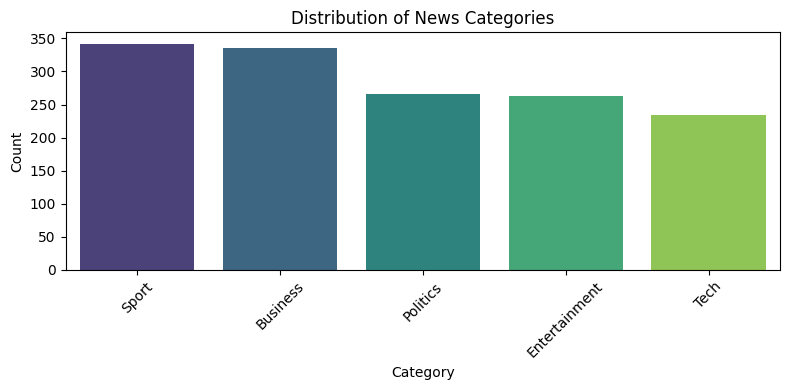


🔍 STUDENT TASK: EXTENDED DATA QUALITY & LENGTH ANALYSIS
1. Missing Values Count:
title       0
content     0
category    0
dtype: int64

2. Content Length Summary (Words):
               count   mean    std    min     max
category                                         
Business       335.0  334.3  133.7  145.0   902.0
Entertainment  263.0  335.4  207.1  144.0  2448.0
Politics       266.0  451.6  261.5   90.0  3345.0
Sport          342.0  336.9  185.9  116.0  1671.0
Tech           234.0  509.2  212.9  188.0  1549.0

3. Duplicate articles removed: 50 | Remaining duplicates: 0

4. Data Integrity: Found 0 empty text entries.


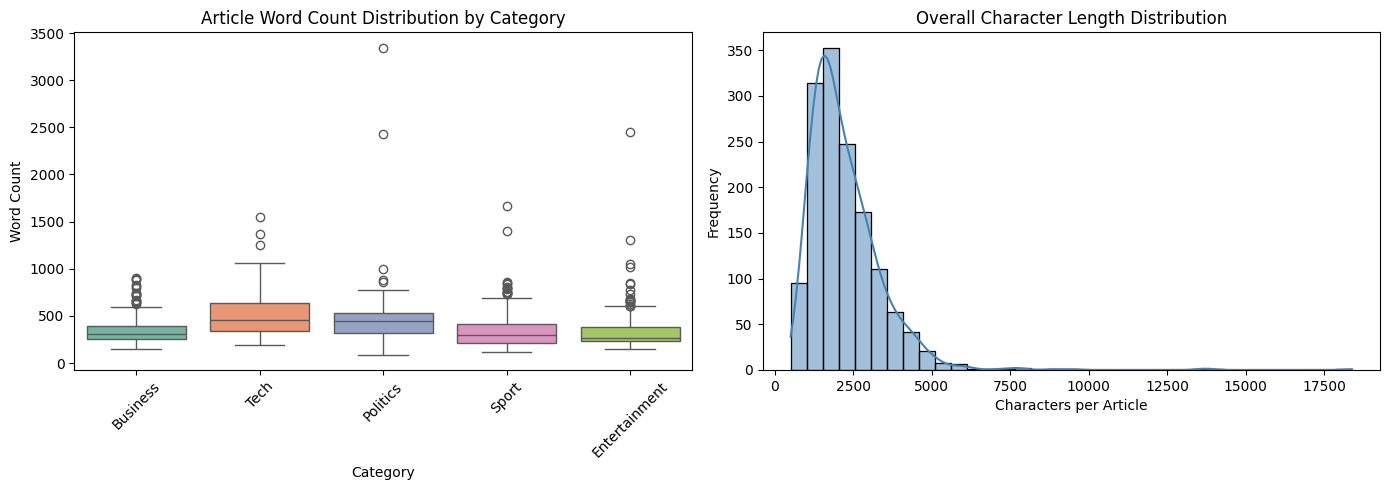

In [5]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Duplicate articles removed during loading: {duplicates_removed}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='category', order=category_counts.index, palette='viridis')
plt.title('Distribution of News Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# 💡 STUDENT TASK: Exploratory Data Analysis
# ==========================================
print("\n🔍 STUDENT TASK: EXTENDED DATA QUALITY & LENGTH ANALYSIS")
print("=" * 50)

# 1. Missing Value Check
missing_summary = df[['title', 'content', 'category']].isnull().sum()
print("1. Missing Values Count:")
print(missing_summary)

# 2. Text Length Feature Engineering (Character & Word Counts)
df['char_length'] = df['content'].apply(lambda x: len(str(x)))
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))

print("\n2. Content Length Summary (Words):")
print(df.groupby('category')['word_count'].describe()[['count', 'mean', 'std', 'min', 'max']].round(1))

# 3. Duplicate Check (duplicates were dropped in the loading cell)
print(f"\n3. Duplicate articles removed: {duplicates_removed} | Remaining duplicates: {df['content'].duplicated().sum()}")
empty_articles = (df['word_count'] == 0).sum()
print(f"\n4. Data Integrity: Found {empty_articles} empty text entries.")

# 4. Multi-panel Visualization of Length Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot of word counts by category (detecting outliers/long articles)
sns.boxplot(data=df, x='category', y='word_count', ax=axes[0], palette='Set2')
axes[0].set_title('Article Word Count Distribution by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Word Count')
axes[0].tick_params(axis='x', rotation=45)

# Histogram of overall character lengths
sns.histplot(df['char_length'], bins=35, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Overall Character Length Distribution')
axes[1].set_xlabel('Characters per Article')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 📝 Analysis: Dataset Exploration

- **Size and balance:** After removing **50 duplicate articles**, we have **1,440 articles** across 5 categories. Sport (342) and Business (335) are the largest, Tech (234) is the smallest. The split is fairly even, so no category dominates training.
- **Why removing duplicates matters:** If the same article ended up in both the training and test sets, the model would be "tested" on something it already memorized, and our accuracy would look better than it really is.
- **Article length:** Tech articles are the longest (about **509 words** on average) and Business the shortest (about 334). Politics has the widest range, from 90 to over 3,300 words.
- **Data quality:** No missing or empty text. One limitation we found: the BBC text is **all lowercase** and has **no real headlines**, so we used the first 8 words of each article as a stand-in title. Both of these affect later steps (see Modules 4, 6 and 8).

### 💬 Discussion: Other Real-World Applications

The same building blocks we used here (sorting text into categories, pulling out names and numbers, and scoring tone) work on almost any kind of written text, not just news. Some examples:

**Financial services and compliance**
- Sort customer complaints, emails, and chat logs by topic (fees, fraud, account access) and send them to the right team automatically.
- Flag messages with strongly negative tone so upset customers get a faster response.
- Scan news for mentions of partner banks, vendors, or countries to spot risks early (sanctions, lawsuits, outages).

**Customer support (any industry)**
- Auto-tag support tickets so they reach the right queue without someone reading every one first.
- Track whether customer sentiment is getting better or worse after a product change.

**Healthcare**
- Organize patient feedback and survey comments by topic (wait times, billing, staff).
- Pull drug names, conditions, and dates out of clinical notes to make records easier to search.

**Legal**
- Sort large batches of documents during discovery and pull out the people, companies, dates, and dollar amounts in each one.

**Human resources**
- Group open-ended employee survey answers by theme and measure overall tone by department.
- Match resumes to job postings based on skills mentioned.

**Marketing and brand monitoring**
- Track what people say about a brand or competitor in reviews and social media, and whether it's positive or negative.

**Government and public services**
- Sort public comments on new rules or 311 requests by topic so staff can respond faster.

**What we learned that applies to all of these:** a model only knows the words it was trained on. Our BBC model learned British politics ("labour," "tory," "blair") and was much less sure about a US Senate article. Any real deployment would need training data from its own field and time period, and someone to review the low-confidence cases.

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [6]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function:
    - Handle null/missing values
    - Lowercase conversion
    - Strip HTML tags and entities
    - Remove URLs and email addresses
    - Strip punctuation, numbers, and symbols
    - Collapse extra whitespace
    """
    if pd.isna(text):
        return ""
    
    # 1. Lowercase
    text = str(text).lower()
    
    # 2. Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)
    
    # 3. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    # 4. Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)
    
    # 5. Remove numbers and special characters (retain only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # 6. Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline:
    - Clean text
    - Tokenize into words
    - Filter stopwords and short tokens (< 3 characters)
    - Lemmatize tokens to root forms
    - Recombine into normalized text string
    """
    # Clean text first
    cleaned = clean_text(text)
    if not cleaned:
        return ""
    
    # Tokenize
    tokens = word_tokenize(cleaned)
    
    # Remove stopwords and filter out tokens with length <= 2
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words and len(token) > 2]
    
    # Lemmatize
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]
        
    return ' '.join(tokens)

# Test the preprocessing function on a sample headline
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


🧹 Preprocessing all 1,440 articles across title and content...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1 (Business):
Original:   worldcom ex-boss launches defence lawyers defending former worldcom worldcom ex-boss launches defenc...
Processed:  worldcom bos launch defence lawyer defending former worldcom worldcom bos launch defence lawyer defe...

Example 2 (Business):
Original:   german business confidence slides german business confidence fell german business confidence slides ...
Processed:  german business confidence slide german business confidence fell german business confidence slide ge...

📊 PREPROCESSING METRICS & VOCABULARY COMPRESSION
Average Characters / Article : 2283.5 ➔ 1524.4 (reduced by 33.2%)
Average Words / Article      : 393.2 ➔ 216.3 (reduced by 45.0%)
Total Unique Vocabulary Size : 35,594 ➔ 20,683 (compressed by 41.9%)


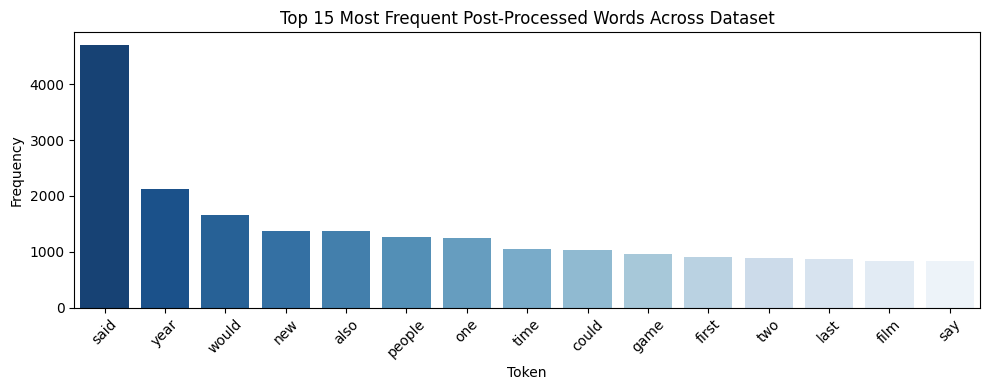

In [7]:
# Apply preprocessing to all articles in the dataset
print(f"🧹 Preprocessing all {len(df):,} articles across title and content...")

# Process titles and content
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine into full text and produce full processed string
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!\n")

# Show before and after examples
print("📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(2):
    print(f"\nExample {i+1} ({df.iloc[i]['category']}):")
    print(f"Original:   {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed:  {df.iloc[i]['full_text_processed'][:100]}...")

# =======================================================
# 💡 STUDENT TASK: Detailed Preprocessing Impact Analysis
# =======================================================
print("\n" + "=" * 60)
print("📊 PREPROCESSING METRICS & VOCABULARY COMPRESSION")
print("=" * 60)

# Calculate length reductions
avg_chars_before = df['full_text'].str.len().mean()
avg_chars_after = df['full_text_processed'].str.len().mean()
avg_words_before = df['full_text'].apply(lambda x: len(str(x).split())).mean()
avg_words_after = df['full_text_processed'].apply(lambda x: len(str(x).split())).mean()

# Calculate unique vocabulary size before and after
vocab_before = set(" ".join(df['full_text']).lower().split())
vocab_after = set(" ".join(df['full_text_processed']).split())

print(f"Average Characters / Article : {avg_chars_before:.1f} ➔ {avg_chars_after:.1f} (reduced by {(1 - avg_chars_after/avg_chars_before)*100:.1f}%)")
print(f"Average Words / Article      : {avg_words_before:.1f} ➔ {avg_words_after:.1f} (reduced by {(1 - avg_words_after/avg_words_before)*100:.1f}%)")
print(f"Total Unique Vocabulary Size : {len(vocab_before):,} ➔ {len(vocab_after):,} (compressed by {(1 - len(vocab_after)/len(vocab_before))*100:.1f}%)")

# Find the 10 most common words post-cleaning across the corpus
all_tokens = " ".join(df['full_text_processed']).split()
top_20_words = Counter(all_tokens).most_common(15)

# Visualize top words
top_words_df = pd.DataFrame(top_20_words, columns=['Word', 'Frequency'])
plt.figure(figsize=(10, 4))
sns.barplot(data=top_words_df, x='Word', y='Frequency', palette='Blues_r')
plt.title('Top 15 Most Frequent Post-Processed Words Across Dataset')
plt.xlabel('Token')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 📝 Analysis: Module 2 – Preprocessing

- Cleaning, removing stop words and lemmatizing cut the average article from **393 words to 216 (about 45% shorter)**, and shrank the vocabulary from **35,594 unique words to 20,683 (about 42% smaller)**.
- That matters because common filler words ("the", "and", "said") carry no topic information. Removing them lets the model focus on words that actually tell categories apart, and makes everything after this run faster.
- Lemmatizing groups word forms together (e.g. "launches" and "launched" become "launch"), so the model treats them as the same idea.
- **Trade-off:** lowercasing and stripping punctuation help classification but throw away clues that grammar and name-finding tools rely on. That's why the POS and entity steps use the original text instead of the cleaned version.

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [8]:
# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=3000,   # Optimal vocabulary size for speed and accuracy
    ngram_range=(1, 2),   # Include both unigrams and bigrams
    min_df=3,             # Ignore terms appearing in fewer than 3 documents
    max_df=0.85           # Ignore terms appearing in over 85% of documents
)

# Fit and transform the preprocessed text
print("🔢 Creating TF-IDF feature matrix...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print("✅ TF-IDF matrix successfully created!")
print(f"📊 Matrix Shape: {tfidf_matrix.shape} (Articles x Terms)")
print(f"📝 Feature Vocabulary Size: {len(feature_names)}")
print(f"🔢 Matrix Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Create a DataFrame for category-level analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF Features (First 3 Articles, First 6 Terms):")
tfidf_df.iloc[:3, :6]

# Show the 8 highest-scoring TF-IDF terms for the first 3 articles
print("\n🔍 Top TF-IDF Terms for the First 3 Articles:")
for i in range(3):
    row = tfidf_matrix[i].toarray().ravel()
    top_idx = row.argsort()[-8:][::-1]
    terms = ", ".join(f"{feature_names[j]} ({row[j]:.3f})" for j in top_idx)
    print(f"\nArticle {i+1} [{df['category'].iloc[i]}]: {terms}")

🔢 Creating TF-IDF feature matrix...
✅ TF-IDF matrix successfully created!
📊 Matrix Shape: (1440, 3000) (Articles x Terms)
📝 Feature Vocabulary Size: 3000
🔢 Matrix Sparsity: 96.24%

🔍 Sample TF-IDF Features (First 3 Articles, First 6 Terms):

🔍 Top TF-IDF Terms for the First 3 Articles:

Article 1 [Business]: worldcom (0.638), accounting (0.372), ebbers (0.364), fraud (0.183), lawyer (0.177), mci (0.119), witness (0.113), charge (0.107)

Article 2 [Business]: german (0.350), confidence (0.343), economy (0.233), business (0.208), index (0.204), rate (0.196), interest rate (0.186), fell (0.163)

Article 3 [Business]: country (0.356), poll (0.320), economy (0.305), economic (0.235), world (0.225), worse (0.215), conducted (0.179), bbc (0.177)


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  • firm              : 0.0419
  • share             : 0.0394
  • company           : 0.0387
  • market            : 0.0367
  • bank              : 0.0367
  • growth            : 0.0351
  • year              : 0.0342
  • economy           : 0.0341

📰 TECH:
  • mobile            : 0.0574
  • phone             : 0.0505
  • people            : 0.0476
  • game              : 0.0437
  • technology        : 0.0428
  • user              : 0.0402
  • net               : 0.0383
  • computer          : 0.0378

📰 POLITICS:
  • labour            : 0.0708
  • election          : 0.0658
  • blair             : 0.0658
  • party             : 0.0543
  • tory              : 0.0514
  • government        : 0.0475
  • would             : 0.0462
  • minister          : 0.0460

📰 SPORT:
  • game              : 0.0466
  • england           : 0.0424
  • win               : 0.0360
  • player            : 0.0333
  • match             : 0.0329
  • champion          : 

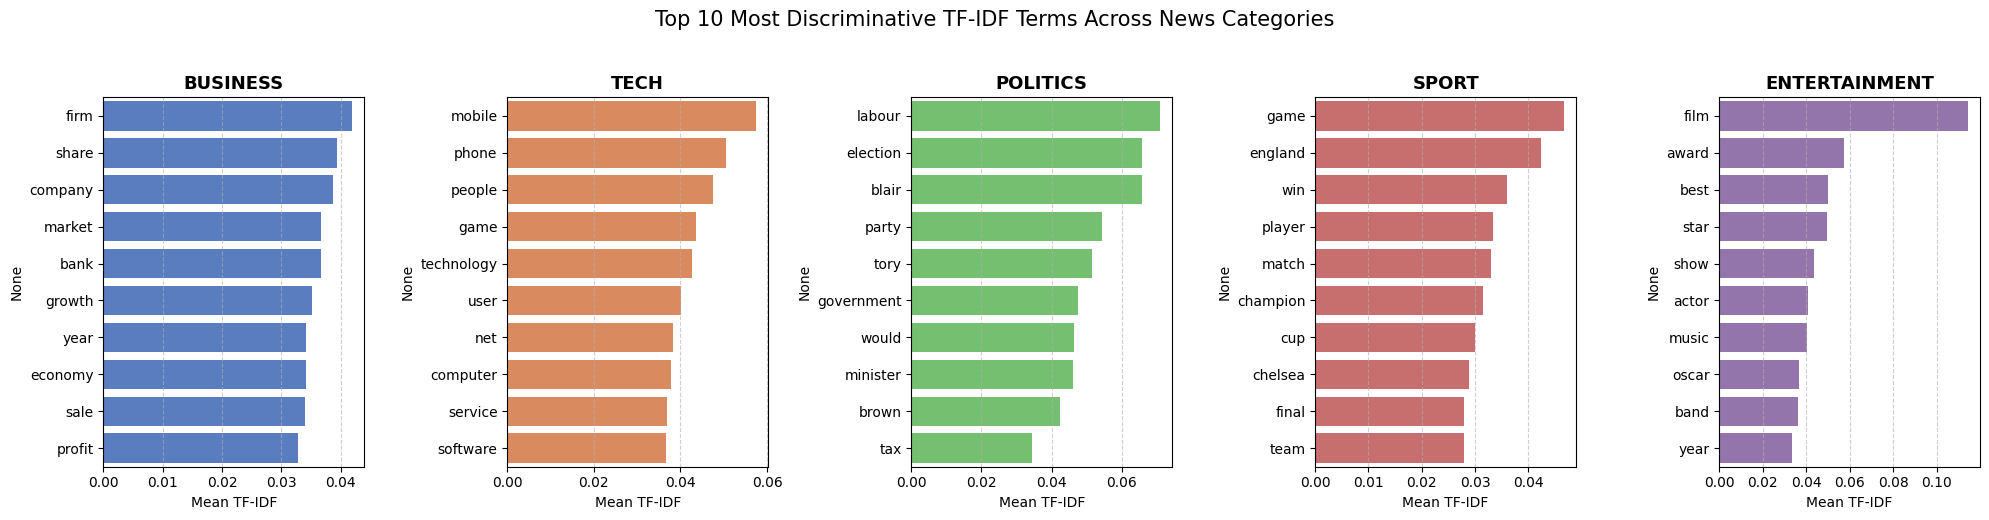

In [9]:
# Analyze the most distinctive terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Isolate articles belonging to a category, compute mean TF-IDF scores,
    and return the top N terms.
    """
    category_data = tfidf_df[tfidf_df['category'] == category]
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)
    return mean_scores.head(n_terms)

print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=8)
    category_terms[category] = top_terms
    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  • {term:<18}: {score:.4f}")

# ==============================================================
# 💡 STUDENT TASK: Visualize Top Distinctive Terms per Category
# ==============================================================
print("\n" + "=" * 50)
print("📊 GENERATING CATEGORY TERM VISUALIZATIONS")
print("=" * 50)

fig, axes = plt.subplots(1, len(categories), figsize=(20, 5), sharey=False)
palette = sns.color_palette("muted", len(categories))

for idx, category in enumerate(categories):
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    sns.barplot(x=top_terms.values, y=top_terms.index, ax=axes[idx], color=palette[idx])
    axes[idx].set_title(f"{category.upper()}", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('Mean TF-IDF')
    axes[idx].grid(axis='x', linestyle='--', alpha=0.6)

plt.suptitle('Top 10 Most Discriminative TF-IDF Terms Across News Categories', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

### 📝 Analysis: Module 3 – TF-IDF

- The top terms per category match what a person would expect, which tells us TF-IDF is picking up real topic signals:
  - **Business:** firm, share, company, market, bank, economy
  - **Politics:** labour, election, blair, party, tory, government
  - **Sport:** game, england, win, player, match, cup
  - **Entertainment:** film, award, best, star, actor, oscar
  - **Tech:** mobile, phone, technology, user, net, computer
- Article-level results look right too. For the first article (the WorldCom fraud trial), the highest-scoring terms are "worldcom", "accounting", "ebbers" and "fraud".
- The matrix is **96% empty (sparsity)**. Each article uses only a small slice of the 3,000-word vocabulary, which is normal for text data.
- **Limitation:** the vocabulary is very British and tied to 2004–2005 news ("labour", "tory", "blair"). This becomes important when we test new articles at the end.

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [10]:
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text:
    - Tokenize raw text
    - Apply POS tagging via NLTK
    - Count tag occurrences
    - Normalize counts into relative proportions
    """
    if not text or pd.isna(text):
        return {}
    
    # Tokenize original text to preserve capitalization for NNP detection
    tokens = word_tokenize(str(text))
    if not tokens:
        return {}
    
    pos_tags = pos_tag(tokens)
    
    # Count frequencies of each POS tag
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)
    
    # Convert raw counts to proportions
    pos_proportions = {pos: count / total_words for pos, count in pos_counts.items()}
    
    return pos_proportions

# Apply POS analysis across all articles
print("🏷️ Analyzing POS patterns across dataset...")

pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame and impute missing tag frequencies with 0
pos_df = pd.DataFrame(pos_results).fillna(0)

print("✅ POS pattern analysis complete!")
print(f"📊 Discovered {len(pos_df.columns) - 2} unique POS tags across the corpus")
pos_df.head()

🏷️ Analyzing POS patterns across dataset...
✅ POS pattern analysis complete!
📊 Discovered 43 unique POS tags across the corpus


,JJ,NNS,NN,VBG,VBD,IN,DT,VBP,VBN,PRP$,...,FW,SYM,WP$,NNP,NNPS,POS,UH,#,``,''
0,0.092593,0.117284,0.231481,0.027778,0.061728,0.108025,0.064815,0.015432,0.040123,0.012346,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.125714,0.068571,0.240000,0.031429,0.060000,0.131429,0.080000,0.014286,0.028571,0.005714,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.079710,0.079710,0.202899,0.025362,0.061594,0.119565,0.096014,0.016304,0.028986,0.016304,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.085546,0.107670,0.156342,0.022124,0.045723,0.120944,0.061947,0.041298,0.017699,0.013274,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.092072,0.079284,0.214834,0.028133,0.035806,0.122762,0.099744,0.015345,0.025575,0.015345,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


📊 POS PATTERNS BY CATEGORY

🎯 Key POS Mean Proportions by Category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.2266  0.0749  0.0011  0.0000  0.0332  0.0403  0.0199  0.0273   
Entertainment  0.2493  0.0584  0.0008  0.0000  0.0282  0.0454  0.0190  0.0293   
Politics       0.2113  0.0689  0.0007  0.0003  0.0454  0.0458  0.0207  0.0302   
Sport          0.2231  0.0491  0.0005  0.0000  0.0404  0.0452  0.0174  0.0247   
Tech           0.1945  0.0859  0.0007  0.0000  0.0419  0.0294  0.0237  0.0264   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
Business       0.0164  0.0246  0.0939  0.0045  0.0032  0.0271  0.0017  0.0006   
Entertainment  0.0189  0.0230  0.0951  0.0025  0.0049  0.0280  0.0010  0.0009   
Politics       0.0203  0.0228  0.0913  0

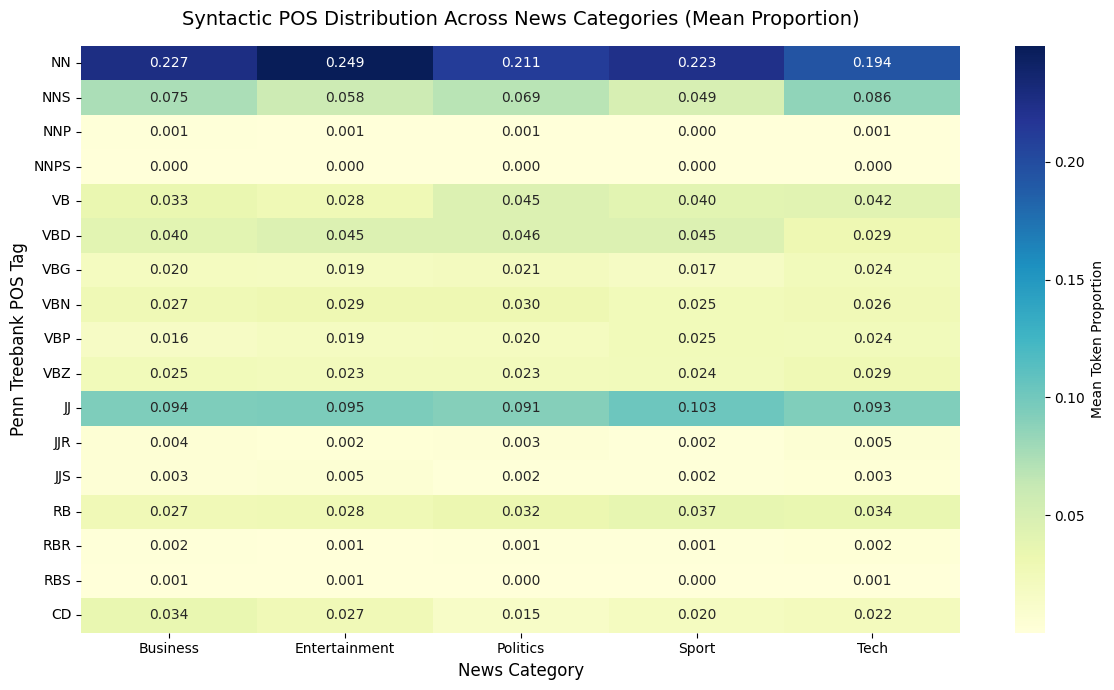


🧠 LINGUISTIC PATTERN FINDINGS:
1. Highest Proper Noun Usage (NNP/NNPS): BUSINESS (note: proper-noun rates are near zero in every category because the BBC text is all lowercase, so the tagger cannot spot names by capital letters)
2. Highest Action Verb Usage (VB*): POLITICS (18.5% of tokens)
3. Highest Descriptive Adjective Usage (JJ*): SPORT (10.7% of tokens)
4. Highest Numerical Token Density (CD): BUSINESS (3.4% of tokens - prices, percentages and financial figures)


In [11]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major grammatical categories:
# Nouns: NN, NNS, NNP, NNPS
# Verbs: VB, VBD, VBG, VBN, VBP, VBZ
# Adjectives: JJ, JJR, JJS
# Adverbs: RB, RBR, RBS
# Numerals: CD
major_pos = [
    'NN', 'NNS', 'NNP', 'NNPS',
    'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
    'JJ', 'JJR', 'JJS',
    'RB', 'RBR', 'RBS',
    'CD'
]

# Filter to available tags
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]
    print("\n🎯 Key POS Mean Proportions by Category:")
    print(pos_summary.round(4))
    
    # Heatmap visualization
    plt.figure(figsize=(12, 7))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlGnBu', fmt='.3f', cbar_kws={'label': 'Mean Token Proportion'})
    plt.title('Syntactic POS Distribution Across News Categories (Mean Proportion)', fontsize=14, pad=15)
    plt.xlabel('News Category', fontsize=12)
    plt.ylabel('Penn Treebank POS Tag', fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # ========================================================
    # 💡 STUDENT TASK: Syntactic Pattern Analysis & Findings
    # ========================================================
    print("\n" + "=" * 50)
    print("🧠 LINGUISTIC PATTERN FINDINGS:")
    print("=" * 50)
    
    # 1. Proper Noun Density
    nnp_cols = [p for p in ['NNP', 'NNPS'] if p in pos_summary.columns]
    top_nnp_cat = pos_summary[nnp_cols].sum(axis=1).idxmax()
    print(f"1. Highest Proper Noun Usage (NNP/NNPS): {top_nnp_cat.upper()} (note: proper-noun rates are near zero in every category because the BBC text is all lowercase, so the tagger cannot spot names by capital letters)")
    
    # 2. Action Verb Density
    verb_cols = [p for p in ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'] if p in pos_summary.columns]
    top_verb_cat = pos_summary[verb_cols].sum(axis=1).idxmax()
    print(f"2. Highest Action Verb Usage (VB*): {top_verb_cat.upper()} ({pos_summary.loc[top_verb_cat, verb_cols].sum():.1%} of tokens)")
    
    # 3. Adjective Usage
    adj_cols = [p for p in ['JJ', 'JJR', 'JJS'] if p in pos_summary.columns]
    top_adj_cat = pos_summary[adj_cols].sum(axis=1).idxmax()
    print(f"3. Highest Descriptive Adjective Usage (JJ*): {top_adj_cat.upper()} ({pos_summary.loc[top_adj_cat, adj_cols].sum():.1%} of tokens)")
    
    # 4. Numerical Density
    if 'CD' in pos_summary.columns:
        top_cd_cat = pos_summary['CD'].idxmax()
        print(f"4. Highest Numerical Token Density (CD): {top_cd_cat.upper()} ({pos_summary.loc[top_cd_cat, 'CD']:.1%} of tokens - prices, percentages and financial figures)")

### 📝 Analysis: Module 4 – Part-of-Speech Patterns

- **Business uses the most numbers** (3.4% of words vs. 1.5% in Politics), which fits stories full of prices, profits and percentages.
- **Sport uses the most adjectives** (about 10.7% of words), from descriptive match reporting ("late", "superb", "dramatic").
- **Politics uses the most verbs** (about 18.5% of words), since political stories focus on what people said, promised and decided.
- **Tech uses the fewest singular nouns but the most plural nouns**, which matches writing about products and users in general ("phones", "users", "services").
- **Key limitation:** proper nouns (names) score close to **0% in every category**. The tagger relies on capital letters to spot names, and the BBC text is all lowercase. On properly capitalized text, we'd expect Sport and Politics to have the most proper nouns (player and politician names).

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [12]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing:
    - Sentence and token counts
    - Syntactic dependency tags (dep_)
    - Noun chunks (grammatical phrases)
    - Grammatical subjects (nsubj, nsubjpass)
    - Grammatical objects (dobj, iobj, pobj)
    """
    if not text or pd.isna(text):
        return {}
    
    # Process text with spaCy English model
    doc = nlp(str(text))
    
    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'subjects': [],
        'objects': []
    }
    
    # Extract dependency relation tags
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)
    
    # Extract noun chunks (phrases)
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())
    
    # Extract grammatical subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:
            features['objects'].append(token.text.lower())
    
    # Count frequency of each dependency type
    features['dependency_counts'] = dict(Counter(features['dependency_relations']))
    
    # Calculate average sentence length (Syntactic Complexity Metric)
    if features['num_sentences'] > 0:
        features['avg_sentence_length'] = features['num_tokens'] / features['num_sentences']
    else:
        features['avg_sentence_length'] = 0.0
        
    return features

print("🌳 Performing syntactic dependency analysis...")

# Random sample of 30 articles per category (fixed seed so results repeat)
sample_indices = []
for cat in df['category'].unique():
    cat_df = df[df['category'] == cat]
    cat_indices = cat_df.sample(n=min(30, len(cat_df)), random_state=42).index
    sample_indices.extend(cat_indices)

sample_for_syntax = df.loc[sample_indices].copy()

syntactic_results = []
for idx, row in sample_for_syntax.iterrows():
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

syntax_df = pd.DataFrame(syntactic_results)
print("✅ Syntactic analysis complete!")
print(f"📊 Processed {len(syntax_df)} stratified articles across categories\n")

# Display first 3 representative syntactic profiles
for i in range(min(3, len(syntactic_results))):
    res = syntactic_results[i]
    print(f"📰 Article {i+1} [{res['category']}]:")
    print(f"  • Sentences: {res['num_sentences']} | Tokens: {res['num_tokens']} | Avg Sent Length: {res['avg_sentence_length']:.1f}")
    print(f"  • Sample Subjects: {res['subjects'][:4]}")
    print(f"  • Sample Objects:  {res['objects'][:4]}")
    print(f"  • Sample Noun Phrases: {res['noun_phrases'][:3]}...\n")

🌳 Performing syntactic dependency analysis...
✅ Syntactic analysis complete!
📊 Processed 150 stratified articles across categories

📰 Article 1 [Business]:
  • Sentences: 12 | Tokens: 328 | Avg Sent Length: 27.3
  • Sample Subjects: ['chief', 'tellier', 'who', 'laurent']
  • Sample Objects:  ['shares', 'chief', 'shares', 'bombardier']
  • Sample Noun Phrases: ['bombardier chief', 'company shares', 'train bombardier chief']...

📰 Article 2 [Business]:
  • Sentences: 12 | Tokens: 317 | Avg Sent Length: 26.4
  • Sample Subjects: ['surge', 'surge', 'consumers', 'commission']
  • Sample Objects:  ['consumers', 'consumers', 'theft', 'figures']
  • Sample Noun Phrases: ['id theft surge', 'us consumers', 'almost a id theft surge']...

📰 Article 3 [Business]:
  • Sentences: 15 | Tokens: 403 | Avg Sent Length: 26.9
  • Sample Subjects: ['banks', 'banks', 'dollar', 'korea']
  • Sample Objects:  ['slide', 'slide', 'ground', 'currencies']
  • Sample Noun Phrases: ['asian banks', 'dollar s slide', '

📝 Parsing Demonstration Sentence: "The company announced a major investment in artificial intelligence today."




📊 SYNTACTIC COMPLEXITY METRICS ACROSS CATEGORIES
               num_sentences  num_tokens  avg_sentence_length
category                                                     
Business               14.30      363.17                25.43
Entertainment          15.77      387.63                25.21
Politics               21.37      542.40                25.73
Sport                  18.17      394.53                22.87
Tech                   21.87      555.23                25.39


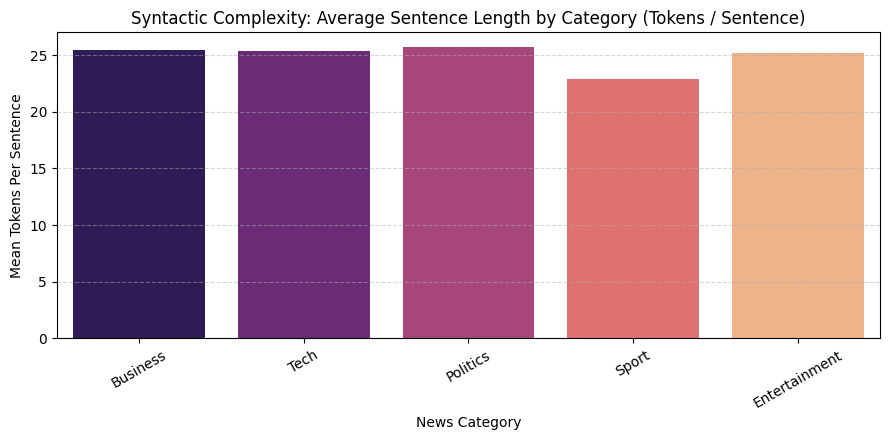

In [13]:
from spacy import displacy

# 1. Visualize a clean sample sentence's dependency structure
sample_sentence = "The company announced a major investment in artificial intelligence today."
print(f"📝 Parsing Demonstration Sentence: \"{sample_sentence}\"\n")
doc_sample = nlp(sample_sentence)

# In Jupyter / Colab notebooks, displacy renders directly
try:
    displacy.render(doc_sample, style="dep", jupyter=True, options={'distance': 110})
except Exception:
    # Text fallback if visual rendering is suppressed
    print("🔗 Syntactic Dependency Triples (Token -> Dep -> Head):")
    for token in doc_sample:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text:<15} --[{token.dep_:<8}]--> {token.head.text}")

# =======================================================
# 💡 STUDENT TASK: Syntactic Complexity Across Categories
# =======================================================
print("\n" + "=" * 55)
print("📊 SYNTACTIC COMPLEXITY METRICS ACROSS CATEGORIES")
print("=" * 55)

complexity_summary = syntax_df.groupby('category')[['num_sentences', 'num_tokens', 'avg_sentence_length']].mean().round(2)
print(complexity_summary)

# Visualize Syntactic Complexity
plt.figure(figsize=(9, 4.5))
sns.barplot(data=syntax_df, x='category', y='avg_sentence_length', palette='magma', errorbar=None)
plt.title('Syntactic Complexity: Average Sentence Length by Category (Tokens / Sentence)', fontsize=12)
plt.xlabel('News Category')
plt.ylabel('Mean Tokens Per Sentence')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 📝 Analysis: Module 5 – Syntax and Sentence Structure

- We parsed a random sample of **30 articles per category** (150 total) to keep run time reasonable.
- **Sport has the shortest sentences** (about **22.9 words per sentence**), while the other categories average about 25–26. Sports writing tends to be quick, punchy play-by-play.
- **Politics and Tech articles have the most sentences** (about 21–22 per article vs. about 14 for Business), so they're longer overall, not just wordier per sentence.
- The parser pulls out subjects and objects ("who did what to whom"). For example, in a Business article it found "banks" and "dollar" as subjects and "slide" and "currencies" as objects. That's the starting point for extracting events from news automatically.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [14]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer:
    - compound: overall normalized score (-1.0 to 1.0)
    - pos, neu, neg: ratio of positive, neutral, and negative words
    - sentiment_label: mapped threshold classification
    """
    if not text or pd.isna(text):
        return {'compound': 0.0, 'pos': 0.0, 'neu': 1.0, 'neg': 0.0, 'sentiment_label': 'neutral'}
    
    scores = sia.polarity_scores(str(text))
    
    # Standard VADER thresholding
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'
        
    return scores

# Apply sentiment analysis to all articles in the dataset
print("😊 Analyzing sentiment across all articles...")

sentiment_results = []
for idx, row in df.iterrows():
    title_sent = analyze_sentiment(row['title'])
    content_sent = analyze_sentiment(row['content'])
    full_sent = analyze_sentiment(row['full_text'])
    
    sentiment_results.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sent['compound'],
        'title_label': title_sent['sentiment_label'],
        'content_sentiment': content_sent['compound'],
        'content_label': content_sent['sentiment_label'],
        'full_sentiment': full_sent['compound'],
        'full_label': full_sent['sentiment_label'],
        'pos_score': full_sent['pos'],
        'neu_score': full_sent['neu'],
        'neg_score': full_sent['neg']
    })

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Processed {len(sentiment_df)} articles across categories\n")

print("📝 Sample Sentiment Results (First 5 Articles):")
sentiment_df[['category', 'title_sentiment', 'full_sentiment', 'full_label']].head()

😊 Analyzing sentiment across all articles...
✅ Sentiment analysis complete!
📊 Processed 1440 articles across categories

📝 Sample Sentiment Results (First 5 Articles):


,category,title_sentiment,full_sentiment,full_label
0,Business,0.1027,-0.9694,negative
1,Business,0.7650,0.8708,positive
2,Business,-0.5574,-0.9454,negative
3,Tech,0.4404,0.9611,positive
4,Business,0.0000,-0.9486,negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment Score Statistics by Category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
Business              0.2307  0.8444 -0.9985  0.9995    0.0930    0.8360   
Entertainment         0.5888  0.6932 -0.9978  0.9999    0.1366    0.8087   
Politics              0.0421  0.8854 -0.9984  0.9999    0.0942    0.8180   
Sport                 0.5484  0.7327 -0.9970  0.9996    0.1347    0.7941   
Tech                  0.5263  0.7525 -0.9991  0.9993    0.0897    0.8596   

              neg_score  
                   mean  
category                 
Business         0.0710  
Entertainment    0.0546  
Politics         0.0878  
Sport            0.0711  
Tech             0.0507  

📊 Sentiment Label Proportions (%) by Category:
full_label     negative  neutral  positive
category        

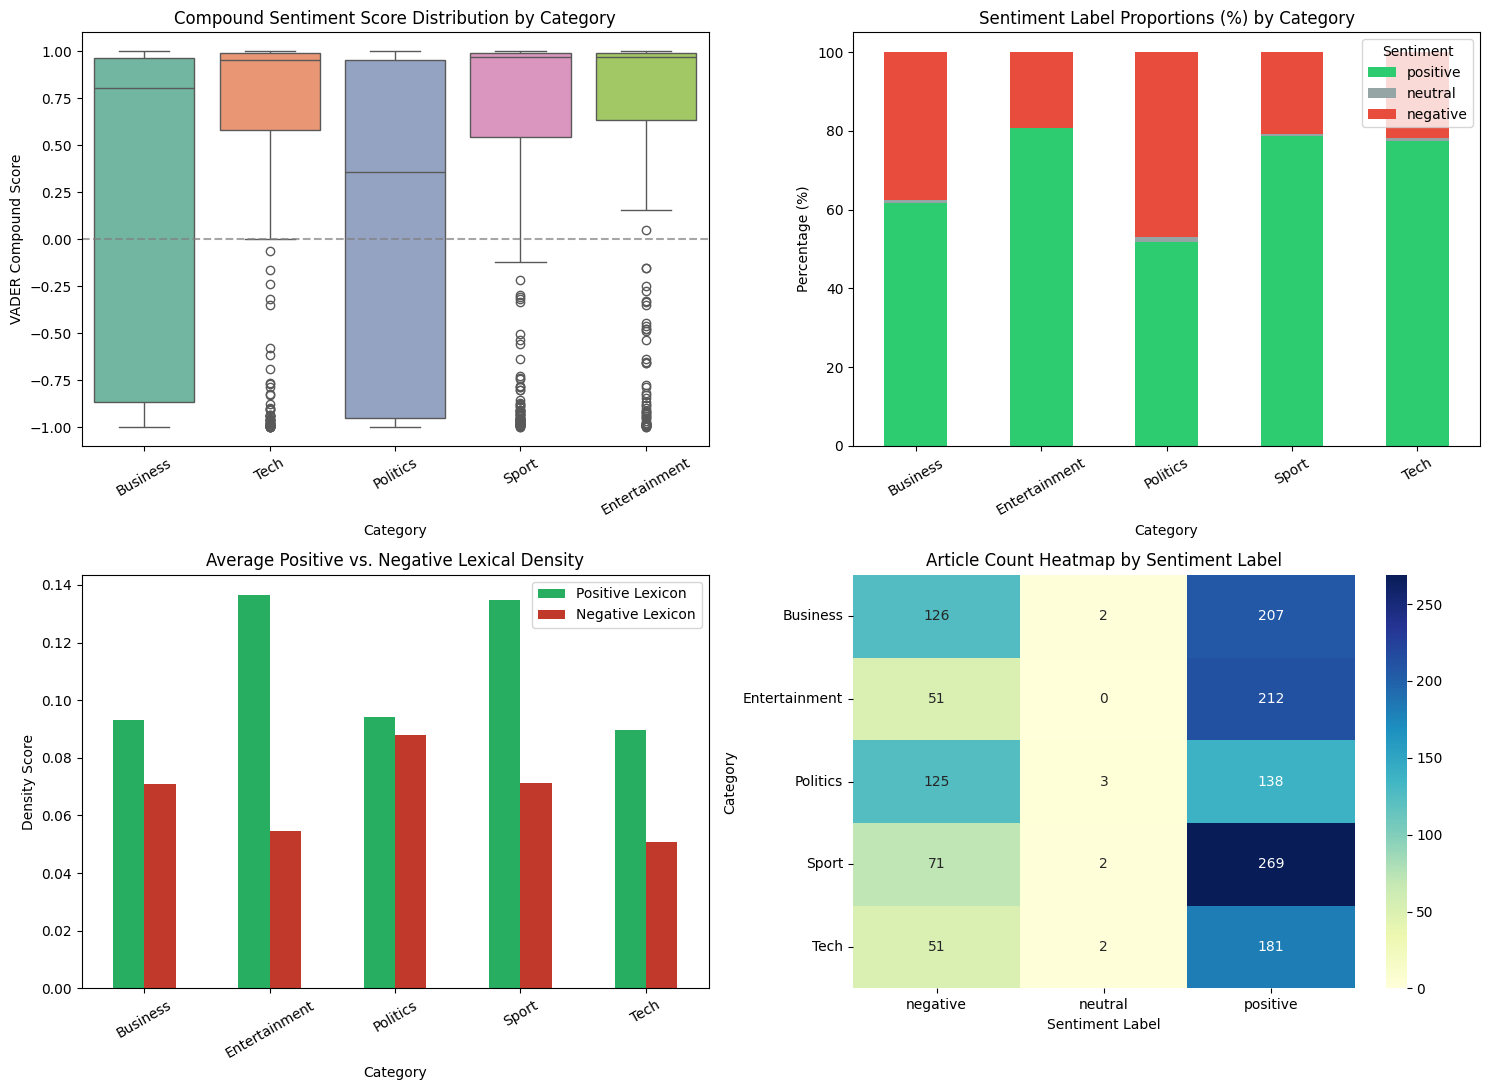


🧠 EDITORIAL SENTIMENT FINDINGS:
• Most Positive Category : ENTERTAINMENT (mean compound 0.589)
• Most Negative Category : POLITICS (mean compound 0.042)
• Title vs. Body: 43% of titles score neutral (too few words for VADER), and title/body sentiment correlation is only 0.41


In [15]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate aggregated sentiment statistics
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment Score Statistics by Category:")
print(sentiment_by_category)

# Percentage distribution of positive, neutral, and negative labels
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment Label Proportions (%) by Category:")
print(sentiment_dist_pct.round(2))

# ==============================================================
# Multi-Panel Visualizations (Module 6 Rubric Requirement)
# ==============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Boxplot: Overall sentiment score distributions
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Compound Sentiment Score Distribution by Category', fontsize=12)
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('VADER Compound Score')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].axhline(0, color='grey', linestyle='--', alpha=0.7)

# 2. Stacked Bar Chart: Sentiment classification percentages
sentiment_dist_pct[['positive', 'neutral', 'negative']].plot(
    kind='bar', stacked=True, ax=axes[0, 1], color=['#2ecc71', '#95a5a6', '#e74c3c']
)
axes[0, 1].set_title('Sentiment Label Proportions (%) by Category', fontsize=12)
axes[0, 1].set_xlabel('Category')
axes[0, 1].set_ylabel('Percentage (%)')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend(title='Sentiment')

# 3. Bar Chart: Comparing positive vs. negative word densities
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1, 0], color=['#27ae60', '#c0392b'])
axes[1, 0].set_title('Average Positive vs. Negative Lexical Density', fontsize=12)
axes[1, 0].set_xlabel('Category')
axes[1, 0].set_ylabel('Density Score')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].legend(['Positive Lexicon', 'Negative Lexicon'])

# 4. Heatmap: Raw counts of articles by category and sentiment
sentiment_pivot = sentiment_df.pivot_table(
    values='article_id', index='category', columns='full_label', aggfunc='count', fill_value=0
)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1, 1], cmap='YlGnBu')
axes[1, 1].set_title('Article Count Heatmap by Sentiment Label', fontsize=12)
axes[1, 1].set_xlabel('Sentiment Label')
axes[1, 1].set_ylabel('Category')

plt.tight_layout()
plt.show()

# ========================================================
# 💡 STUDENT TASK: Editorial & Tone Insights
# ========================================================
print("\n" + "=" * 50)
print("🧠 EDITORIAL SENTIMENT FINDINGS:")
print("=" * 50)
most_pos = sentiment_df.groupby('category')['full_sentiment'].mean().idxmax()
most_neg = sentiment_df.groupby('category')['full_sentiment'].mean().idxmin()

cat_means = sentiment_df.groupby('category')['full_sentiment'].mean()
print(f"• Most Positive Category : {most_pos.upper()} (mean compound {cat_means[most_pos]:.3f})")
print(f"• Most Negative Category : {most_neg.upper()} (mean compound {cat_means[most_neg]:.3f})")

# Title vs. body: titles here are the first 8 words of each article (BBC has no headlines)
title_neutral = (sentiment_df['title_sentiment'].abs() < 0.05).mean()
corr = sentiment_df['title_sentiment'].corr(sentiment_df['full_sentiment'])
print(f"• Title vs. Body: {title_neutral:.0%} of titles score neutral (too few words for VADER), "
      f"and title/body sentiment correlation is only {corr:.2f}")

### 📝 Analysis: Module 6 – Sentiment

- **Entertainment is the most positive** category (average score 0.589, 81% of articles positive), followed closely by Sport (79%) and Tech (77%).
- **Politics is the most negative** (average 0.042), with **47% of articles scoring negative**, almost half. Business is next at 38% negative, from stories about losses, layoffs and fraud.
- **Almost nothing scores neutral** (under 1.2% in every category). VADER adds up emotional words, so long articles tend to tip strongly one way or the other. A full-length news story is rarely scored as "neutral" even if it's written in a neutral tone.
- **Titles vs. articles:** 43% of our "titles" scored neutral, and title and body sentiment only line up at **0.41**. That's mostly because our titles are just the first 8 words of the article, which is too little text for VADER to judge.
- **Business takeaway:** a sentiment score on its own isn't proof of bias. Politics news is negative partly because it covers conflict and disputes, not because the reporting is slanted.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [16]:
from sklearn.preprocessing import MinMaxScaler

print("🔧 Preparing combined features for multi-class classification...")

# 1. TF-IDF Features
X_tfidf = tfidf_matrix.toarray()

# 2. Sentiment Features (Min-Max scaled so scores are >= 0 for MultinomialNB compatibility)
scaler_sent = MinMaxScaler()
sentiment_raw = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values
sentiment_scaled = scaler_sent.fit_transform(sentiment_raw)

# 3. Document Length Features (Characters, Words, Title Length)
scaler_len = MinMaxScaler()
length_raw = np.array([
    df['full_text'].str.len(),
    df['full_text'].str.split().str.len(),
    df['title'].str.len()
]).T
length_scaled = scaler_len.fit_transform(length_raw)

# 4. Horizontally stack all feature spaces together
X_combined = np.hstack([
    X_tfidf,
    sentiment_scaled,
    length_scaled
])

# Target labels
y = df['category'].values

print("✅ Feature matrix prepared successfully!")
print(f"📊 Combined Feature Matrix Shape: {X_combined.shape} (Samples x Features)")
print(f"🎯 Number of Classes: {len(np.unique(y))} {np.unique(y).tolist()}")

# Stratified 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\n📈 Dataset Split:")
print(f"  • Training Samples : {X_train.shape[0]}")
print(f"  • Testing Samples  : {X_test.shape[0]}")

🔧 Preparing combined features for multi-class classification...
✅ Feature matrix prepared successfully!
📊 Combined Feature Matrix Shape: (1440, 3007) (Samples x Features)
🎯 Number of Classes: 5 ['Business', 'Entertainment', 'Politics', 'Sport', 'Tech']

📈 Dataset Split:
  • Training Samples : 1152
  • Testing Samples  : 288


In [17]:
print("🤖 Training and evaluating multi-class models...")

# Define classifiers to evaluate
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, C=1.0),
    'Support Vector Machine': SVC(kernel='linear', probability=True, random_state=42)
}

results = {}
trained_models = {}

for name, clf in classifiers.items():
    print(f"\n🔄 Training {name}...")
    
    # Fit model on training set
    clf.fit(X_train, y_train)
    
    # Predict on test set
    y_pred = clf.predict(X_test)
    y_pred_proba = clf.predict_proba(X_test) if hasattr(clf, 'predict_proba') else None
    
    # Evaluate metrics
    test_acc = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    
    results[name] = {
        'accuracy': test_acc,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }
    trained_models[name] = clf
    
    print(f"  ✅ Test Accuracy : {test_acc:.4f}")
    print(f"  📊 5-Fold CV Mean: {cv_scores.mean():.4f} (±{cv_scores.std()*2:.4f})")

print("\n" + "=" * 55)
print("🏆 MODEL BENCHMARK COMPARISON TABLE")
print("=" * 55)

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[m]['accuracy'] for m in results.keys()],
    '5-Fold CV Mean': [results[m]['cv_mean'] for m in results.keys()],
    '5-Fold CV Std': [results[m]['cv_std'] for m in results.keys()]
})

print(comparison_df.round(4).to_string(index=False))

best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
best_model = trained_models[best_model_name]
print(f"\n🥇 Best Performing Model: {best_model_name} ({results[best_model_name]['accuracy']:.2%} Accuracy)")

🤖 Training and evaluating multi-class models...

🔄 Training Naive Bayes...
  ✅ Test Accuracy : 0.9340
  📊 5-Fold CV Mean: 0.9627 (±0.0171)

🔄 Training Logistic Regression...
  ✅ Test Accuracy : 0.9375
  📊 5-Fold CV Mean: 0.9566 (±0.0228)

🔄 Training Support Vector Machine...
  ✅ Test Accuracy : 0.9514
  📊 5-Fold CV Mean: 0.9653 (±0.0135)

🏆 MODEL BENCHMARK COMPARISON TABLE
                 Model  Test Accuracy  5-Fold CV Mean  5-Fold CV Std
           Naive Bayes         0.9340          0.9627         0.0086
   Logistic Regression         0.9375          0.9566         0.0114
Support Vector Machine         0.9514          0.9653         0.0068

🥇 Best Performing Model: Support Vector Machine (95.14% Accuracy)


📊 DETAILED EVALUATION REPORT: SUPPORT VECTOR MACHINE
               precision    recall  f1-score   support

     Business     0.9420    0.9701    0.9559        67
Entertainment     0.9434    0.9434    0.9434        53
     Politics     0.9608    0.9245    0.9423        53
        Sport     0.9444    1.0000    0.9714        68
         Tech     0.9767    0.8936    0.9333        47

     accuracy                         0.9514       288
    macro avg     0.9535    0.9463    0.9493       288
 weighted avg     0.9520    0.9514    0.9511       288



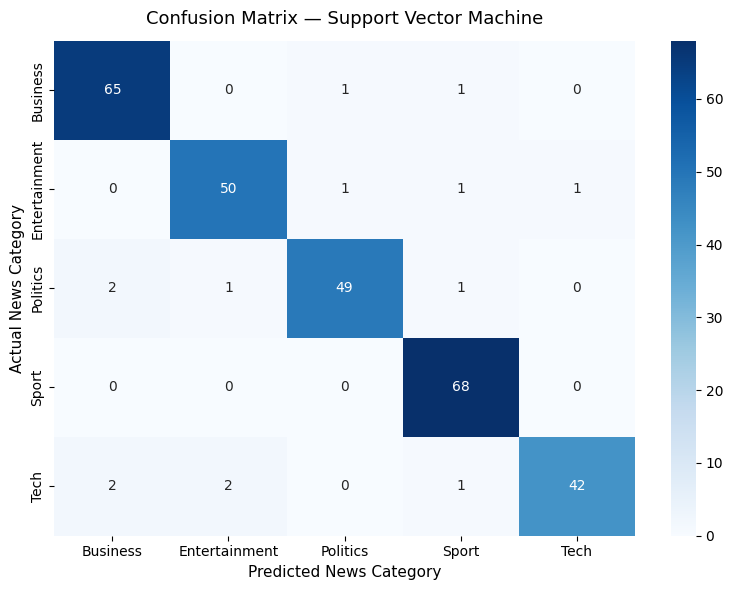


🔍 TOP 8 PREDICTIVE FEATURES PER CATEGORY (Logistic Regression weights)

📰 BUSINESS:
   firm, bank, company, share, economy, profit, market, economic

📰 ENTERTAINMENT:
   film, show, star, music, singer, band, album, actor

📰 POLITICS:
   labour, blair, election, party, minister, government, tory, secretary

📰 SPORT:
   match, player, coach, england, feat_title_len, chelsea, cup, injury

📰 TECH:
   mobile, user, computer, feat_char_len, technology, software, phone, feat_word_count


In [18]:
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION REPORT: {best_model_name.upper()}")
print("=" * 60)

# 1. Classification Metrics Breakdown
print(classification_report(y_test, best_predictions, digits=4))

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, best_predictions, labels=best_model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=best_model.classes_, 
    yticklabels=best_model.classes_
)
plt.title(f'Confusion Matrix — {best_model_name}', fontsize=13, pad=12)
plt.xlabel('Predicted News Category', fontsize=11)
plt.ylabel('Actual News Category', fontsize=11)
plt.tight_layout()
plt.show()

# 3. Interpretability: Top Predictive Features per Category
# Note: a linear SVM with 5 classes stores one weight row per PAIR of classes (10 rows),
# so its rows don't line up with the class names. Logistic Regression stores one row
# per class, so we use it to show which words drive each category.
interp_model = trained_models['Logistic Regression']

print("\n" + "=" * 60)
print("🔍 TOP 8 PREDICTIVE FEATURES PER CATEGORY (Logistic Regression weights)")
print("=" * 60)

# Combine feature names: TF-IDF terms + Sentiment + Length
extended_feature_names = list(feature_names) + [
    'feat_compound', 'feat_pos', 'feat_neu', 'feat_neg',
    'feat_char_len', 'feat_word_count', 'feat_title_len'
]

for i, class_name in enumerate(interp_model.classes_):
    top_indices = np.argsort(interp_model.coef_[i])[-8:][::-1]  # 8 highest positive weights
    top_terms = [extended_feature_names[idx] for idx in top_indices]
    print(f"\n📰 {class_name.upper()}:")
    print("   " + ", ".join(top_terms))


### 📝 Analysis: Module 7 – Classification

- All three models did well. **SVM was best at 95.1% test accuracy**, with Logistic Regression at 93.8% and Naive Bayes at 93.4%. In 5-fold cross-validation, all three scored between 95.7% and 96.5%, so the results are consistent and not a lucky test split.
- SVM also had the **smallest spread across folds**, meaning it's the most stable choice.
- **By category:** Sport was easiest (100% of sport articles found). **Tech was hardest at 89% recall**: 5 of the 47 Tech test articles were put in another category. Tech stories often overlap with Business (company earnings, mergers), so this makes sense.
- **What drives each prediction:** the strongest words per category are easy to explain (Politics: labour, blair, election; Entertainment: film, singer, album). Interestingly, **article length** shows up in the top features for Tech and Sport. Tech articles are much longer on average, and the model learned to use that.
- **Note on the feature list:** we used Logistic Regression's weights here because the SVM stores its weights per *pair* of categories, not per category, so its list can't be read the same way.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [19]:
def extract_entities(text):
    """
    Extract named entities using spaCy's pre-trained pipeline:
    - PERSON: People and public figures
    - ORG: Companies, institutions, agencies
    - GPE: Geopolitical entities (countries, cities, states)
    - DATE: Absolute or relative dates
    - MONEY: Monetary values
    """
    if not text or pd.isna(text):
        return []
    
    doc = nlp(str(text))
    return [{
        'text': ent.text.strip(),
        'label': ent.label_,
        'start': ent.start_char,
        'end': ent.end_char,
        'description': spacy.explain(ent.label_)
    } for ent in doc.ents if len(ent.text.strip()) > 1]

print("🔍 Extracting named entities across all articles...")

all_entities = []
article_entities = []

# High-speed batch processing via nlp.pipe (disabling parser since we only need ner)
texts = df['full_text'].astype(str).tolist()
categories = df['category'].tolist()
article_ids = df['article_id'].tolist()

for doc, cat, art_id in zip(nlp.pipe(texts, batch_size=50, disable=['parser']), categories, article_ids):
    doc_ents = [{
        'text': ent.text.strip(),
        'label': ent.label_,
        'start': ent.start_char,
        'end': ent.end_char,
        'description': spacy.explain(ent.label_),
        'article_id': art_id,
        'category': cat
    } for ent in doc.ents if len(ent.text.strip()) > 1]
    
    article_entities.append({
        'article_id': art_id,
        'category': cat,
        'entities': doc_ents,
        'entity_count': len(doc_ents)
    })
    all_entities.extend(doc_ents)

entities_df = pd.DataFrame(all_entities)

print("✅ Entity extraction complete!")
print(f"📊 Total Entities Discovered: {len(entities_df):,}")
print(f"📰 Total Articles Processed: {len(article_entities):,}")
print(f"🏷️ Unique Entity Labels Found: {entities_df['label'].unique().tolist()}\n")

print("📝 Sample Extracted Entities (First 8 Rows):")
entities_df[['text', 'label', 'category', 'description']].head(8)

🔍 Extracting named entities across all articles...
✅ Entity extraction complete!
📊 Total Entities Discovered: 41,532
📰 Total Articles Processed: 1,440
🏷️ Unique Entity Labels Found: ['ORDINAL', 'PERSON', 'GPE', 'DATE', 'MONEY', 'ORG', 'NORP', 'LOC', 'CARDINAL', 'PERCENT', 'TIME', 'EVENT', 'QUANTITY', 'FAC', 'PRODUCT', 'LANGUAGE', 'WORK_OF_ART', 'LAW']

📝 Sample Extracted Entities (First 8 Rows):


,text,label,category,description
0,first,ORDINAL,Business,"""first"", ""second"", etc."
1,cynthia cooper,PERSON,Business,"People, including fictional"
2,us,GPE,Business,"Countries, cities, states"
3,2002,DATE,Business,Absolute or relative dates or periods
4,5.7bn,MONEY,Business,"Monetary values, including unit"
5,new york,GPE,Business,"Countries, cities, states"
6,wednesday,DATE,Business,Absolute or relative dates or periods
7,arthur andersen,PERSON,Business,"People, including fictional"


📊 NAMED ENTITY RECOGNITION ANALYSIS

🏷️ Top 10 Entity Labels by Total Frequency:
label
DATE        8588
PERSON      8116
GPE         5718
CARDINAL    5600
ORG         4489
NORP        2857
MONEY       1682
ORDINAL     1630
PERCENT     1249
TIME         587
Name: count, dtype: int64

📰 Entity Counts by Category (Primary Labels):
label          CARDINAL  DATE   GPE  MONEY  NORP   ORG  PERSON
category                                                      
Business           1044  2420  1661    914   721  1469     992
Entertainment      1015  1680   799    332   442   657    1869
Politics            791  1324   958    215   730   596    1956
Sport              1558  1984  1577     36   684   717    2643
Tech               1192  1180   723    185   280  1050     656

🔥 Top 10 Most Mentioned Specific Entities:
  • first                     [ORDINAL]: 749 mentions
  • one                       [CARDINAL]: 645 mentions
  • two                       [CARDINAL]: 594 mentions
  • us               

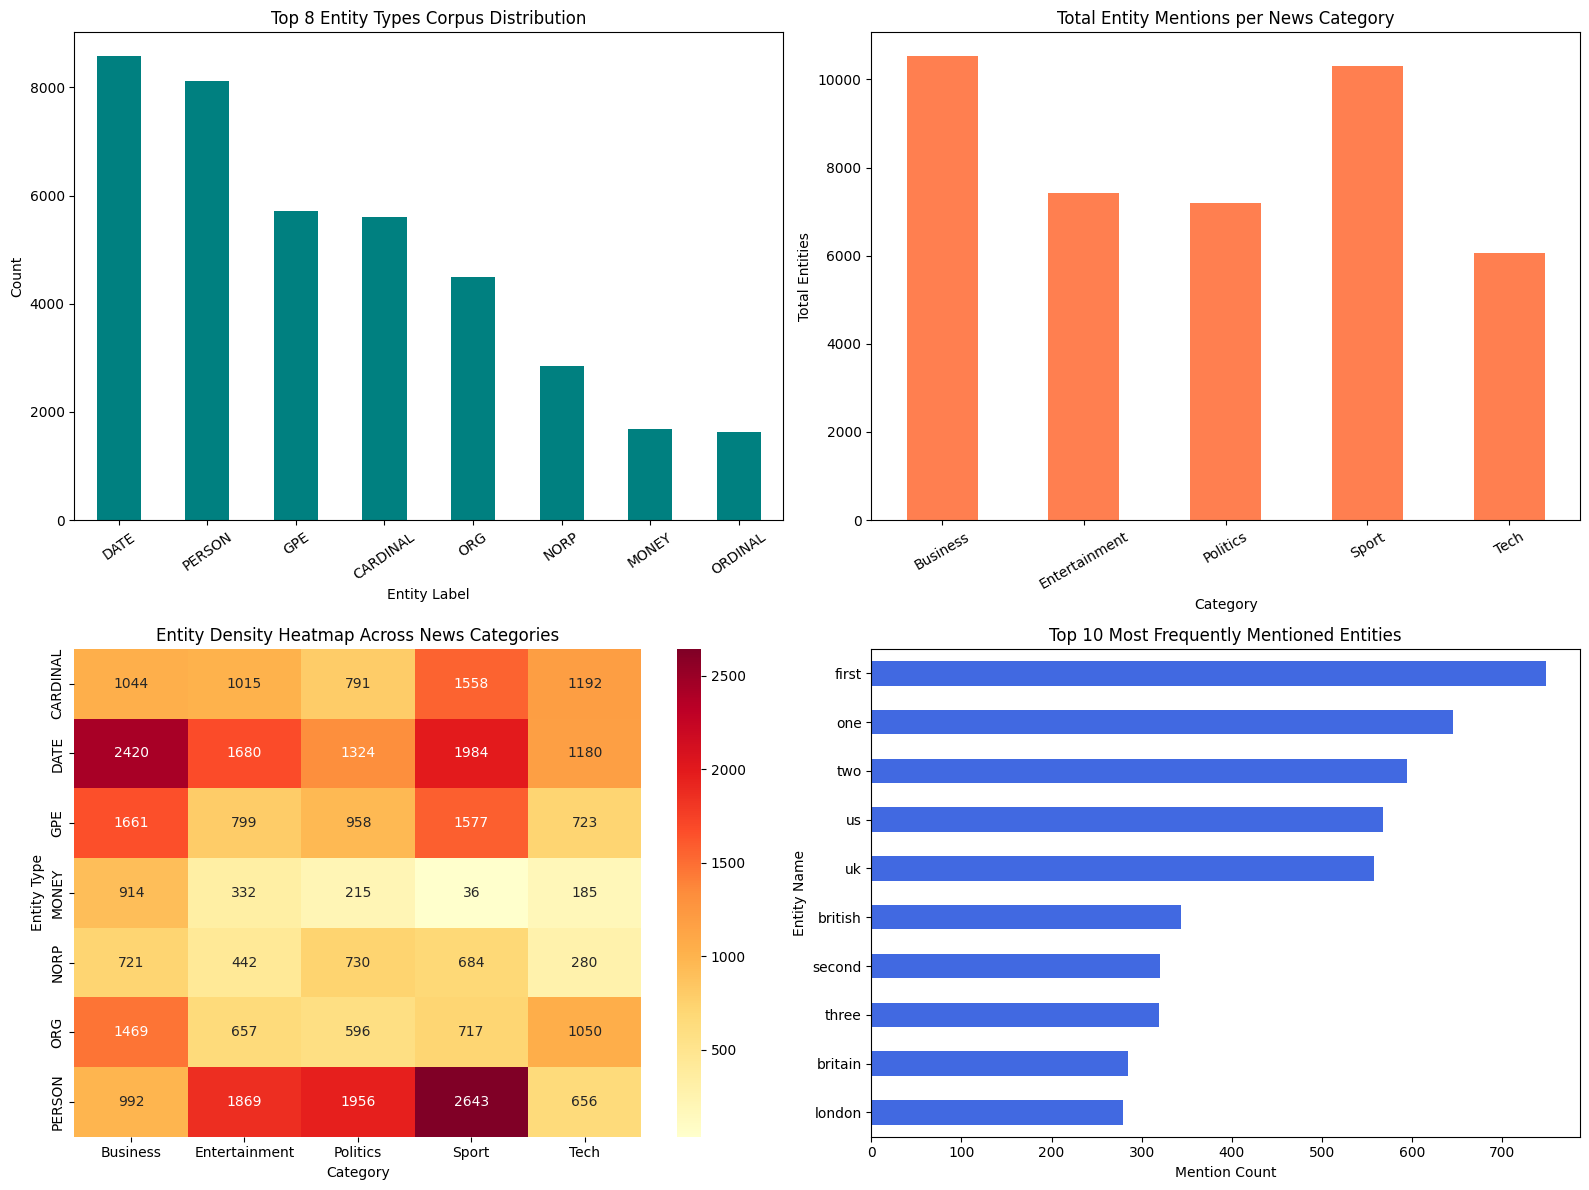


🧠 BUSINESS ENTITY TAKEAWAYS:
• Highest Organization Density (ORG): BUSINESS (1,469 mentions) — useful for company and competitor tracking
• Highest Geopolitical Density (GPE): BUSINESS (1,661 mentions) — useful for regional and market monitoring


In [20]:
if not entities_df.empty:
    print("📊 NAMED ENTITY RECOGNITION ANALYSIS")
    print("=" * 55)
    
    # 1. Distribution of Entity Labels
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Top 10 Entity Labels by Total Frequency:")
    print(entity_counts.head(10))
    
    # 2. Key entity types across categories
    primary_labels = ['PERSON', 'ORG', 'GPE', 'DATE', 'MONEY', 'CARDINAL', 'NORP']
    filtered_entities = entities_df[entities_df['label'].isin(primary_labels)]
    entity_by_category = filtered_entities.groupby(['category', 'label']).size().unstack(fill_value=0)
    
    print("\n📰 Entity Counts by Category (Primary Labels):")
    print(entity_by_category)
    
    # 3. Top Most Frequent Entities Overall
    print("\n🔥 Top 10 Most Mentioned Specific Entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(10)
    for (ent_text, label), count in frequent_entities.items():
        print(f"  • {ent_text:<25} [{label}]: {count} mentions")
        
    # ==============================================================
    # 4-Panel Visualization Dashboard (Module 8 Rubric Requirement)
    # ==============================================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Panel 1: Top 8 Entity Types Distribution
    entity_counts.head(8).plot(kind='bar', ax=axes[0, 0], color='teal')
    axes[0, 0].set_title('Top 8 Entity Types Corpus Distribution', fontsize=12)
    axes[0, 0].set_xlabel('Entity Label')
    axes[0, 0].set_ylabel('Count')
    axes[0, 0].tick_params(axis='x', rotation=35)
    
    # Panel 2: Total Entities per News Category
    entities_per_cat = entities_df.groupby('category').size()
    entities_per_cat.plot(kind='bar', ax=axes[0, 1], color='coral')
    axes[0, 1].set_title('Total Entity Mentions per News Category', fontsize=12)
    axes[0, 1].set_xlabel('Category')
    axes[0, 1].set_ylabel('Total Entities')
    axes[0, 1].tick_params(axis='x', rotation=30)
    
    # Panel 3: Heatmap of Entity Types across Categories
    sns.heatmap(entity_by_category.T, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1, 0])
    axes[1, 0].set_title('Entity Density Heatmap Across News Categories', fontsize=12)
    axes[1, 0].set_xlabel('Category')
    axes[1, 0].set_ylabel('Entity Type')
    
    # Panel 4: Top 10 Most Frequent Named Entities
    top_10_mentions = entities_df['text'].value_counts().head(10)
    top_10_mentions.sort_values().plot(kind='barh', ax=axes[1, 1], color='royalblue')
    axes[1, 1].set_title('Top 10 Most Frequently Mentioned Entities', fontsize=12)
    axes[1, 1].set_xlabel('Mention Count')
    axes[1, 1].set_ylabel('Entity Name')
    
    plt.tight_layout()
    plt.show()
    
    # ========================================================
    # 💡 STUDENT TASK: Entity Pattern Takeaways
    # ========================================================
    print("\n" + "=" * 55)
    print("🧠 BUSINESS ENTITY TAKEAWAYS:")
    print("=" * 55)
    top_org_cat = entity_by_category['ORG'].idxmax() if 'ORG' in entity_by_category.columns else "N/A"
    top_gpe_cat = entity_by_category['GPE'].idxmax() if 'GPE' in entity_by_category.columns else "N/A"
    print(f"• Highest Organization Density (ORG): {top_org_cat.upper()} ({entity_by_category.loc[top_org_cat, 'ORG']:,} mentions) — useful for company and competitor tracking")
    print(f"• Highest Geopolitical Density (GPE): {top_gpe_cat.upper()} ({entity_by_category.loc[top_gpe_cat, 'GPE']:,} mentions) — useful for regional and market monitoring")
else:
    print("⚠️ No entities extracted.")

### 📝 Analysis: Module 8 – Named Entities

- spaCy found **41,532 entities** across the 1,440 articles. Dates (8,588) and people (8,116) are the most common.
- The patterns by category make sense:
  - **Sport mentions the most people** (2,643: players, coaches) and almost no money (36).
  - **Business has the most money amounts** (914), the most organizations (1,469) and the most places (1,661), reflecting company and market news across countries.
  - **Politics has the second-most people** (1,956: politicians, ministers).
- **Limitation:** the "most mentioned entities" list is mostly counting words like "first", "one" and "two", which isn't useful. And because the text is lowercase, the model counts **"us"** as the country 568 times, when many of those are probably the word "us". For real business use, we'd filter to people, organizations and places and use properly capitalized text.
- Even with these issues, entity extraction turns unstructured articles into searchable facts (who, which company, where, how much).

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [21]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic & text length features
    """
    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'business_recommendations': []
    }
    
    # 1. Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': float(df['full_text'].str.len().mean()),
        'avg_words_per_article': float(df['full_text'].str.split().str.len().mean())
    }
    
    # 2. Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': float(results[best_model_name]['accuracy']),
        'model_comparison': {name: float(results[name]['accuracy']) for name in results.keys()}
    }
    
    # 3. Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': float(sentiment_df['full_sentiment'].mean())
    }
    
    # 4. Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': int(entities_df['text'].nunique()),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }
    
    # 5. Business Recommendations
    recommendations = []
    
    # Classification recommendation
    acc = insights['classification_performance']['best_accuracy']
    if acc >= 0.85:
        recommendations.append(f"✅ High classification accuracy ({acc:.1%}) achieved by {best_model_name} — ready for automated production content routing.")
    else:
        recommendations.append("⚠️ Classification performance suggests expanding domain training data before routing live feeds.")
        
    # Sentiment recommendation
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} coverage shows the highest positive sentiment — optimal for consumer engagement streams.")
    recommendations.append(f"📊 {neg_cat} coverage shows elevated negative sentiment — critical for risk monitoring and balanced reporting audits.")
    
    # Entity recommendation
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Dense entity extraction enables automated knowledge graph mapping and competitor tracking.")
        
    insights['business_recommendations'] = recommendations
    return insights

print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()
print("✅ Analysis complete!\n")

print("=" * 65)
print("📈 NEWSBOT INTELLIGENCE SYSTEM — EXECUTIVE REPORT")
print("=" * 65)

overview = analysis_results['dataset_overview']
print(f"\n📊 DATASET OVERVIEW:")
print(f"  • Total Articles Analyzed : {overview['total_articles']}")
print(f"  • Monitored Categories    : {', '.join(overview['categories'])}")
print(f"  • Average Words / Article : {overview['avg_words_per_article']:.0f}")

perf = analysis_results['classification_performance']
print(f"\n🤖 CLASSIFICATION BENCHMARK:")
print(f"  • Winning Architecture    : {perf['best_model']}")
print(f"  • Benchmark Test Accuracy : {perf['best_accuracy']:.2%}")

sent = analysis_results['sentiment_insights']
print(f"\n😊 SENTIMENT LANDSCAPE:")
print(f"  • Most Positive Category  : {sent['most_positive_category']}")
print(f"  • Most Critical Category  : {sent['most_negative_category']}")
print(f"  • Corpus Compound Mean    : {sent['overall_sentiment']:.3f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    ent = analysis_results['entity_insights']
    print(f"\n🔍 ENTITY EXTRACTION:")
    print(f"  • Total Entities Indexed  : {ent['total_entities']:,}")
    print(f"  • Unique Extracted Names  : {ent['unique_entities']:,}")
    print(f"  • Monitored Entity Labels : {', '.join(ent['entity_types'][:6])}")

print(f"\n💡 STRATEGIC BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM — EXECUTIVE REPORT

📊 DATASET OVERVIEW:
  • Total Articles Analyzed : 1440
  • Monitored Categories    : Business, Tech, Politics, Sport, Entertainment
  • Average Words / Article : 393

🤖 CLASSIFICATION BENCHMARK:
  • Winning Architecture    : Support Vector Machine
  • Benchmark Test Accuracy : 95.14%

😊 SENTIMENT LANDSCAPE:
  • Most Positive Category  : Entertainment
  • Most Critical Category  : Politics
  • Corpus Compound Mean    : 0.385

🔍 ENTITY EXTRACTION:
  • Total Entities Indexed  : 41,532
  • Unique Extracted Names  : 12,129
  • Monitored Entity Labels : ORDINAL, PERSON, GPE, DATE, MONEY, ORG

💡 STRATEGIC BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy (95.1%) achieved by Support Vector Machine — ready for automated production content routing.
  2. 📊 Entertainment coverage shows the highest positive sentiment — optimal for consumer engagement streams.
  3. 📊 Politics co

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [22]:
class NewsBotIntelligenceSystem:
    """
    End-to-End NewsBot Intelligence Production Pipeline:
    - Preprocessing & normalization
    - Feature extraction (TF-IDF + live Sentiment + live Length scaling)
    - Multi-class category classification with confidence score
    - Named Entity Recognition (NER)
    - Sentiment & tone analysis
    - Actionable insight generation
    """
    def __init__(self, classifier, vectorizer, sentiment_analyzer, scaler_sent, scaler_len, spacy_nlp):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sia = sentiment_analyzer
        self.scaler_sent = scaler_sent
        self.scaler_len = scaler_len
        self.nlp = spacy_nlp
    
    def preprocess_article(self, title, content):
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text
    
    def classify_article(self, full_text, title, processed_text):
        # 1. TF-IDF vectorization
        tfidf_features = self.vectorizer.transform([processed_text]).toarray()
        
        # 2. Live sentiment calculation & scaling
        s = self.sia.polarity_scores(full_text)
        raw_sentiment = np.array([[s['compound'], s['pos'], s['neu'], s['neg']]])
        sentiment_features = self.scaler_sent.transform(raw_sentiment)
        
        # 3. Live length calculation & scaling
        raw_length = np.array([[len(full_text), len(full_text.split()), len(title)]])
        length_features = self.scaler_len.transform(raw_length)
        
        # 4. Stack into complete multimodal feature vector
        features_combined = np.hstack([tfidf_features, sentiment_features, length_features])
        
        # Prediction & class probabilities
        prediction = self.classifier.predict(features_combined)[0]
        if hasattr(self.classifier, "predict_proba"):
            probabilities = self.classifier.predict_proba(features_combined)[0]
            class_probs = dict(zip(self.classifier.classes_, probabilities))
        else:
            class_probs = {prediction: 1.0}
            
        return prediction, class_probs
    
    def extract_entities(self, text):
        return extract_entities(text)
    
    def analyze_sentiment(self, text):
        return analyze_sentiment(text)
    
    def generate_insights(self, category, entities, sentiment, category_probs):
        insights = []
        confidence = max(category_probs.values())
        
        if confidence > 0.70:
            insights.append(f"✅ High classification confidence for {category.upper()} ({confidence:.1%})")
        else:
            insights.append(f"⚠️ Low confidence ({confidence:.1%}) — routed for editorial review")
            
        compound = sentiment['compound']
        if compound >= 0.05:
            insights.append(f"😊 Overall Positive emotional tone (compound: {compound:.3f})")
        elif compound <= -0.05:
            insights.append(f"😞 Critical / Negative tone detected (compound: {compound:.3f})")
        else:
            insights.append(f"😐 Neutral, matter-of-fact journalistic tone (compound: {compound:.3f})")
            
        if entities:
            key_entities = [e['text'] for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if key_entities:
                unique_keys = list(dict.fromkeys(key_entities))[:3]
                insights.append(f"🎯 Key Target Entities: {', '.join(unique_keys)}")
            insights.append(f"🔍 Discovered {len(entities)} structured entity mentions")
        else:
            insights.append("ℹ️ No named entities detected")
            
        return insights
    
    def process_article(self, title, content):
        full_text, processed_text = self.preprocess_article(title, content)
        category, category_probs = self.classify_article(full_text, title, processed_text)
        entities = self.extract_entities(full_text)
        sentiment = self.analyze_sentiment(full_text)
        insights = self.generate_insights(category, entities, sentiment, category_probs)
        
        return {
            'title': title,
            'content': content[:180] + '...' if len(content) > 180 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

# Initialize production pipeline instance
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia,
    scaler_sent=scaler_sent,
    scaler_len=scaler_len,
    spacy_nlp=nlp
)

print("🤖 NewsBot Intelligence System initialized successfully!")
print("✅ Ready to process real-time incoming news articles")

🤖 NewsBot Intelligence System initialized successfully!
✅ Ready to process real-time incoming news articles


In [23]:
# Test the complete system with new, unseen articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

test_articles = [
    {
        'title': 'Nvidia Unveils Next-Gen AI Chips and Accelerated Rendering Architecture',
        'content': 'Nvidia announced its latest graphics hardware and GPU architecture designed for neural rendering and generative AI workloads. CEO Jensen Huang highlighted massive efficiency gains in 3D ray tracing and enterprise computing.'
    },
    {
        'title': 'Award-Winning Director Announces Sequel to Box Office Hit',
        'content': 'The acclaimed filmmaker confirmed at a press event in London that filming on the sequel will begin next spring, with most of the original cast returning. Studio executives expect a major summer release and strong ticket sales.'
    },
    {
        'title': 'Houston Astros Rally in the Ninth Inning for Dramatic Postseason Victory',
        'content': 'The Houston Astros scored three runs with two outs in the bottom of the ninth inning to secure a 5-4 win. Pitching depth and timely home runs propelled the team closer to the championship series.'
    },
    {
        'title': 'Senate Committee Debates Bipartisan Privacy and Antitrust Legislation',
        'content': 'Members of Congress gathered on Capitol Hill today to debate new regulatory frameworks for consumer privacy and corporate monopolies. Several lawmakers called for strict oversight and immediate legislative votes.'
    },
    {
        # Deliberately ambiguous: could be Tech or Business
        'title': 'Apple Shares Climb After Record iPhone Sales Lift Quarterly Profits',
        'content': 'Apple reported quarterly revenue of 95 billion dollars, beating analyst forecasts as demand for its latest smartphones and online services grew. Investors pushed the company stock up four percent in early trading.'
    }
]

# Process each test article through the full pipeline
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 50)
    
    result = newsbot.process_article(article['title'], article['content'])
    
    print(f"Headline: {result['title']}")
    print(f"Content:  {result['content']}")
    print(f"\n🏷️  Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")
    
    print("\n📊 Class Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  • {cat:<12}: {prob:.3f}")
        
    print(f"\n😊 Sentiment Analysis:")
    print(f"  • Label: {result['sentiment']['sentiment_label'].upper()} (Compound: {result['sentiment']['compound']:.3f})")
    print(f"  • Pos: {result['sentiment']['pos']} | Neu: {result['sentiment']['neu']} | Neg: {result['sentiment']['neg']}")
    
    if result['entities']:
        print(f"\n🔍 Discovered Entities ({len(result['entities'])}):")
        for ent in result['entities'][:5]:  # Display top 5
            desc = ent.get('description', 'Named Entity')
            print(f"  • {ent['text']} [{ent['label']}] — {desc}")
    else:
        print("\n🔍 No named entities detected")
        
    print(f"\n💡 System Insights:")
    for insight in result['insights']:
        print(f"  • {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System pipeline tests complete!")
print("✅ Ready for video walkthrough demonstration and submission.")

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
--------------------------------------------------
Headline: Nvidia Unveils Next-Gen AI Chips and Accelerated Rendering Architecture
Content:  Nvidia announced its latest graphics hardware and GPU architecture designed for neural rendering and generative AI workloads. CEO Jensen Huang highlighted massive efficiency gains ...

🏷️  Predicted Category: Tech (46.86% confidence)

📊 Class Probabilities:
  • Tech        : 0.469
  • Business    : 0.216
  • Sport       : 0.194
  • Entertainment: 0.084
  • Politics    : 0.037

😊 Sentiment Analysis:
  • Label: POSITIVE (Compound: 0.599)
  • Pos: 0.114 | Neu: 0.886 | Neg: 0.0

🔍 Discovered Entities (5):
  • Nvidia Unveils Next-Gen AI Chips [ORG] — Companies, agencies, institutions, etc.
  • Accelerated Rendering Architecture Nvidia [ORG] — Companies, agencies, institutions, etc.
  • GPU [ORG] — Companies, agencies, institutions, etc.
  • AI [GPE] — Countries, cities, states
  • Jensen Huang [

### 📝 Analysis: Testing the Full System on New Articles

| Test article | Prediction | Confidence | What it tells us |
|---|---|---|---|
| Film sequel announcement | Entertainment | 95.5% | Clear topic words ("film", "cast") → very confident |
| Houston Astros win | Sport | 96.2% | Works even though BBC covers mostly UK sports |
| Apple earnings (could be Tech *or* Business) | Business | 97.3% | Money words ("shares", "profits", "revenue") outweighed "iPhone" |
| Nvidia AI chips | Tech | 46.9% | Right answer, but unsure: "AI" and "GPU" barely appear in 2004–2005 news |
| US Senate debate | Politics | 45.2% | Right answer, but unsure: the model learned UK politics ("labour", "tory"), not "Congress" or "Senate" |

- **All five predictions were correct**, but the confidence levels show the system's real weakness: it only knows the words in its training data. New topics (AI) and a different country's politics (US) make it unsure.
- The system handled this well by flagging both low-confidence articles for **human review** instead of silently guessing. That's how it should work in a real newsroom.
- The entity results show the lowercase-training problem from the other direction: on these properly capitalized test articles, spaCy grabs whole headlines as organizations (e.g. "Houston Astros Rally" and "Senate Committee Debates Bipartisan Privacy" tagged as ORG).
- **To improve:** retrain on recent, US-inclusive news and run entity extraction on body text only, not headline + body.

## 🌐 Bonus: NewsBot Web App (Gradio)

A simple web page for NewsBot, so anyone can use it without touching code. Paste a headline and article text (or click one of the example articles), then click **Analyze**. The app shows:

- **Predicted category** with the probability for each of the 5 categories
- **Tone** (positive / neutral / negative) with the sentiment scores
- **Entities** highlighted right inside the article text, color-coded by type (person, organization, place, date, money…)
- **Insights**, including the low-confidence flag for articles that need a human review

It uses the same `newsbot` object built above, so the results match the notebook exactly.


In [ ]:
# 🌐 NewsBot Web App (Gradio)
# Paste any news article into the boxes and click "Analyze" to run the full NewsBot pipeline.
import gradio as gr

def analyze_article(title, content):
    """Run one article through NewsBot and format the results for the web app."""
    title, content = (title or "").strip(), (content or "").strip()
    if not content:
        return {}, "⚠️ Please paste some article text first.", None, ""

    result = newsbot.process_article(title, content)
    full_text = f"{title} {content}"   # the same text NewsBot used, so entity positions line up

    # 1. Category probabilities (shown as a bar list)
    category_probs = {cat: float(p) for cat, p in result['category_probabilities'].items()}

    # 2. Sentiment summary
    s = result['sentiment']
    sentiment_md = (f"### {s['sentiment_label'].capitalize()}\n"
                    f"Overall score: **{s['compound']:.2f}** (−1 = very negative, +1 = very positive)\n\n"
                    f"Positive {s['pos']:.0%} · Neutral {s['neu']:.0%} · Negative {s['neg']:.0%}")

    # 3. Entities highlighted inside the article text
    highlighted = {
        "text": full_text,
        "entities": [{"entity": e['label'], "start": e['start'], "end": e['end']}
                     for e in result['entities']]
    }

    # 4. Insights
    insights_md = "\n".join(f"- {i}" for i in result['insights'])

    return category_probs, sentiment_md, highlighted, insights_md


with gr.Blocks(title="NewsBot Intelligence System") as newsbot_app:
    gr.Markdown("# 🤖 NewsBot Intelligence System\n"
                "Paste a news article to see its **category**, **tone**, and the **people, companies and places** it mentions. "
                "Trained on BBC News (Business, Entertainment, Politics, Sport, Tech).")
    with gr.Row():
        with gr.Column():
            title_in = gr.Textbox(label="Headline", placeholder="Paste the headline here")
            content_in = gr.Textbox(label="Article text", lines=10, placeholder="Paste the first few paragraphs here")
            analyze_btn = gr.Button("Analyze", variant="primary")
        with gr.Column():
            category_out = gr.Label(label="Predicted category", num_top_classes=5)
            sentiment_out = gr.Markdown(label="Tone")
    entities_out = gr.HighlightedText(label="Entities found", combine_adjacent=False, show_legend=True)
    insights_out = gr.Markdown(label="Insights")

    gr.Examples(
        examples=[[a['title'], a['content']] for a in test_articles],
        inputs=[title_in, content_in],
        label="Try one of our test articles"
    )

    analyze_btn.click(analyze_article,
                      inputs=[title_in, content_in],
                      outputs=[category_out, sentiment_out, entities_out, insights_out])

# Opens the app inside the notebook (and at a local web address)
newsbot_app.launch()


## 📝 Project Summary

### What we built
NewsBot takes in a news article and, in one step, (1) cleans the text, (2) predicts its category, (3) measures its tone, and (4) pulls out the people, organizations, places, dates and money amounts it mentions. It then gives a short list of insights, including flagging articles it isn't sure about for human review.

### Key results
- **Dataset:** 1,440 BBC News articles (after removing 50 duplicates), 5 categories
- **Best model:** Support Vector Machine, **95.1% test accuracy** (95.7–96.5% across all models in cross-validation)
- **Sentiment:** Entertainment is the most positive category; Politics is the most negative (47% of articles negative)
- **Entities:** 41,532 extracted; Sport is most person-focused, Business most money- and company-focused
- **New articles:** all 5 test articles classified correctly; the 2 about topics missing from the training data (AI, US politics) were correctly flagged as low confidence

### Web app
A Gradio web app (above) lets anyone paste in an article and see the category, tone, entities and insights, with no code.

### Main limitations
1. **All-lowercase text** hurts name-finding (proper nouns near 0%, "us" counted as a country).
2. **No real headlines.** We used the first 8 words as titles, which weakens the title sentiment comparison.
3. **Old, UK-only news** (2004–2005), so the model is less confident on newer topics and US news.
4. **VADER sentiment** leans to extremes on long articles and can't tell negative *events* from negative *reporting*.

### Future improvements
- Retrain on recent news from more countries, with original capitalization and headlines
- Try a transformer model (e.g. BERT) for better handling of new topics and context
- Track entities and sentiment over time to spot trends

### Business value
- **Newsrooms and content teams:** automatically tag and route articles, sending unclear ones to an editor
- **Business intelligence:** monitor news about specific companies, people or countries, and whether coverage is positive or negative
- **Risk and compliance:** flag negative coverage of partners, vendors or markets early